# **Latin Grammar Question Intent Classifier** - Training

Fine-tuning a BERT-based model for intent classification to identify user grammatical queries. Loads the processed datasets, fine-tunes BERT for sequence classification, plots the loss curve, and saves the trained model.

## **Import Dependencies**

In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"

In [ ]:
import sys
import transformers
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments, AutoModelForSequenceClassification, AutoTokenizer, EarlyStoppingCallback
import datasets
from datasets import load_from_disk
import json
# import pandas as pd
# import numpy as np
import torch

# import sklearn
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, classification_report
# import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

In [ ]:
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
os.chdir('/content/drive/MyDrive/FYP')

In [ ]:
from huggingface_hub import login
from google.colab import userdata

login(token=userdata.get('HF_TOKEN'))

In [ ]:
print(torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

True
Using device: cuda


In [ ]:
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
# print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
# print("seaborn:", sns.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Python: 3.12.13
PyTorch: 2.10.0+cu128
Transformers: 5.0.0
Datasets: 4.0.0
scikit-learn: 1.6.1
pandas: 2.2.2
NumPy: 2.0.2
Matplotlib: 3.10.0
seaborn: 0.13.2
CUDA: 12.8
GPU: Tesla T4


## **Load Processed Data**

In [ ]:
# Load tokenized datasets and intent metadata saved
PROCESSED_DIR = "./processed_intent"

train_dataset = load_from_disk(f"{PROCESSED_DIR}/train_dataset")
val_dataset   = load_from_disk(f"{PROCESSED_DIR}/val_dataset")

with open(f"{PROCESSED_DIR}/intent2label.json") as f:
    intent2label = json.load(f)
label2intent = {i: intent for intent, i in intent2label.items()}
intents = sorted(intent2label.keys())

print(f"{len(train_dataset)} train | {len(val_dataset)} val")
print("Total number of intents:", len(intents))

In [ ]:
# load tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

## **Model**

### Load Model

In [ ]:
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=len(intents),
    id2label=label2intent,
    label2id=intent2label,
    hidden_dropout_prob=0.2,
    attention_probs_dropout_prob=0.2
    )

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# define training args
args = TrainingArguments(
    output_dir="./intent_classifier",       # Directory to save model checkpoints
    eval_strategy="epoch",                  # Evaluate on validation set every epoch
    save_strategy="epoch",                  # Save model checkpoints every epoch
    learning_rate=4e-5,                     # Learning rate
    warmup_steps=0.1,                       # Proportion of training steps to linearly increase learning rate
    per_device_train_batch_size=32,         # Batch size for training
    gradient_accumulation_steps=1,
    label_smoothing_factor=0.1,             # to prevent overconfidence
    num_train_epochs=10,                    # Number of training epochs
    weight_decay=0.1,                       # Regularization to prevent overfitting
    load_best_model_at_end=True,            # Load the best model based on evaluation metrics
    save_total_limit=1,                     # Maximum number of checkpoints to keep - keeps best and most recent
    fp16=True                               # Enable mixed precision for faster training
)

### Training

In [ ]:
def compute_metrics(eval_pred):
  logits, labels = eval_pred
  preds = logits.argmax(axis=1)
  return {
    "accuracy": accuracy_score(labels, preds),
    "f1": f1_score(labels, preds, average="weighted"),
  }

In [ ]:
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,2.393224,0.130682,0.099580
2,No log,1.671579,0.801136,0.751847
3,No log,0.946460,0.943182,0.929926
4,No log,0.619737,0.994318,0.994174
5,No log,0.547883,1.000000,1.000000
6,No log,0.552220,0.994318,0.994174
7,No log,0.547109,0.994318,0.994174
8,No log,0.545087,0.994318,0.994174
9,No log,0.544742,0.994318,0.994174
10,No log,0.545297,0.994318,0.994174


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

TrainOutput(global_step=260, training_loss=1.024195040189303, metrics={'train_runtime': 189.5897, 'train_samples_per_second': 43.199, 'train_steps_per_second': 1.371, 'total_flos': 210456349740000.0, 'train_loss': 1.024195040189303, 'epoch': 10.0})

### Plot Training vs Validation Loss Curve

In [ ]:
trainer.state.log_history

[{'eval_loss': 2.393223524093628,
  'eval_accuracy': 0.13068181818181818,
  'eval_f1': 0.09957960940086065,
  'eval_runtime': 0.4418,
  'eval_samples_per_second': 398.408,
  'eval_steps_per_second': 49.801,
  'epoch': 1.0,
  'step': 26},
 {'eval_loss': 1.6715785264968872,
  'eval_accuracy': 0.8011363636363636,
  'eval_f1': 0.7518468982818096,
  'eval_runtime': 0.451,
  'eval_samples_per_second': 390.202,
  'eval_steps_per_second': 48.775,
  'epoch': 2.0,
  'step': 52},
 {'eval_loss': 0.9464603662490845,
  'eval_accuracy': 0.9431818181818182,
  'eval_f1': 0.9299258553734794,
  'eval_runtime': 1.7928,
  'eval_samples_per_second': 98.171,
  'eval_steps_per_second': 12.271,
  'epoch': 3.0,
  'step': 78},
 {'eval_loss': 0.6197366118431091,
  'eval_accuracy': 0.9943181818181818,
  'eval_f1': 0.9941735537190083,
  'eval_runtime': 0.6456,
  'eval_samples_per_second': 272.615,
  'eval_steps_per_second': 34.077,
  'epoch': 4.0,
  'step': 104},
 {'eval_loss': 0.5478832721710205,
  'eval_accuracy'

In [ ]:
# get training log history
log_history = trainer.state.log_history

train_epochs = []
train_loss = []

val_epochs = []
val_loss = []

for entry in log_history:
    # training loss
    if "loss" in entry and "epoch" in entry:
        train_epochs.append(entry["epoch"])
        train_loss.append(entry["loss"])

    # validation loss
    if "eval_loss" in entry:
        val_epochs.append(entry["epoch"])
        val_loss.append(entry["eval_loss"])

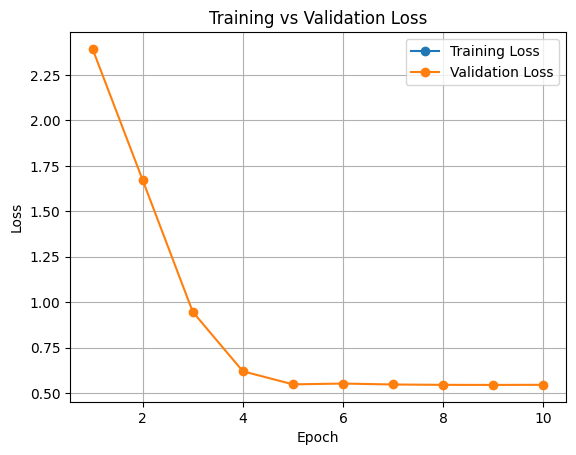

In [ ]:
# plot training vs val loss
plt.figure()

plt.plot(train_epochs, train_loss, marker='o', label="Training Loss")
plt.plot(val_epochs, val_loss, marker='o', label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

### Evaluate Finetuned Model

In [ ]:
# evaluate finetuned model
results = trainer.evaluate()
results

{'eval_loss': 0.5447378754615784,
 'eval_accuracy': 0.9943181818181818,
 'eval_f1': 0.9941735537190083,
 'eval_runtime': 2.1869,
 'eval_samples_per_second': 80.478,
 'eval_steps_per_second': 10.06,
 'epoch': 10.0}

### Save Model

In [ ]:
# save the model and tokenizer
model.save_pretrained("./intent_classifier")
tokenizer.save_pretrained("./intent_classifier")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./intent_classifier/tokenizer_config.json',
 './intent_classifier/tokenizer.json')